In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [33]:
#import the dataset
df = pd.read_csv("emails.csv")
print(df.head())

                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1


In [34]:
#basic info of the dataset dataframe outline
print("shape :",df.shape)
print("\n columns :")
print(df.columns)
print("\information:")
df.info()

shape : (5728, 2)

 columns :
Index(['text', 'spam'], dtype='object')
\information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [35]:
print("missing values :")
print(df.isnull().sum())

missing values :
text    0
spam    0
dtype: int64


In [36]:
print("duplicate rows:")
print(df.duplicated().sum())

duplicate rows:
33


In [37]:
#drop the duplicates which was found above
df = df.drop_duplicates()
df = df.dropna()
df = df.reset_index(drop=True)
print(df.head())

                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1
2  Subject: unbelievable new homes made easy  im ...     1
3  Subject: 4 color printing special  request add...     1
4  Subject: do not have money , get software cds ...     1


In [38]:
print("duplicate rows:")
print(df.duplicated().sum())

duplicate rows:
0


In [39]:
df["length"]=df["text"].str.len()
print(df.head())

                                                text  spam  length
0  Subject: naturally irresistible your corporate...     1    1484
1  Subject: the stock trading gunslinger  fanny i...     1     598
2  Subject: unbelievable new homes made easy  im ...     1     448
3  Subject: 4 color printing special  request add...     1     500
4  Subject: do not have money , get software cds ...     1     235


In [40]:
#convert the length column to numpy to perform aggregate functions
lengths = df["length"].to_numpy()
print("mean length :",np.mean(lengths))
print("max length :",np.max(lengths))
print("min length :",np.min(lengths))
print("median length :",np.median(lengths))

mean length : 1558.0670763827918
max length : 43952
min length : 13
median length : 979.0


In [45]:
print("square root of lemgths :")
print(np.sqrt(lengths[:10]))
print("squared length :")
print(np.square(lengths[:10]))
print(df["spam"].value_counts())

square root of lemgths :
[38.52272057 24.45403852 21.16601049 22.36067977 15.32970972 21.86321111
 96.64367543 21.11871208 22.5166605  21.11871208]
squared length :
[ 2202256   357604   200704   250000    55225   228484 87235600   198916
   257049   198916]
spam
0    4327
1    1368
Name: count, dtype: int64


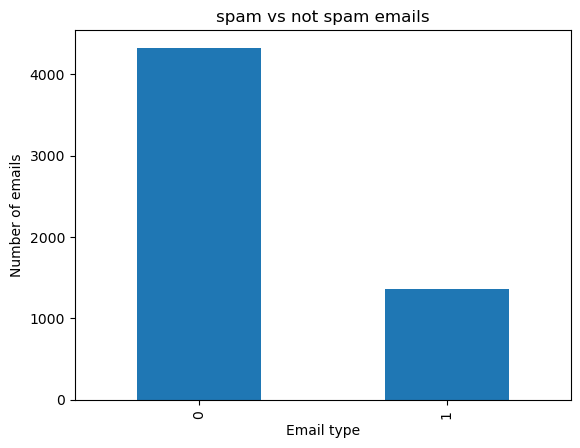

In [47]:
df["spam"].value_counts().plot(kind="bar")
plt.title("spam vs not spam emails")
plt.xlabel("Email type")
plt.ylabel("Number of emails")
plt.show()

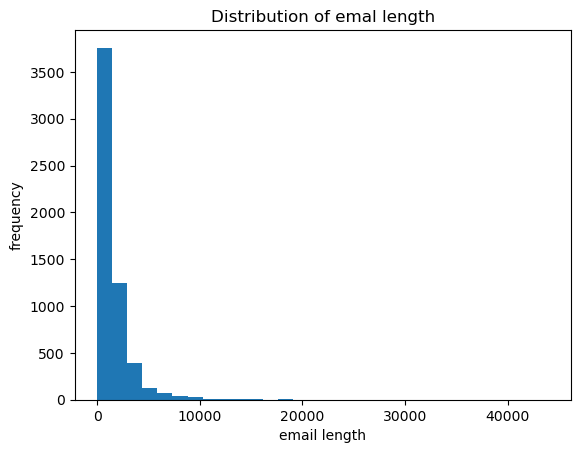

In [59]:
plt.hist(df["length"],bins = 30)
plt.title("Distribution of emal length")
plt.xlabel("email length")
plt.ylabel("frequency")
plt.show()

spam
0    1634.200139
1    1317.257310
Name: length, dtype: float64


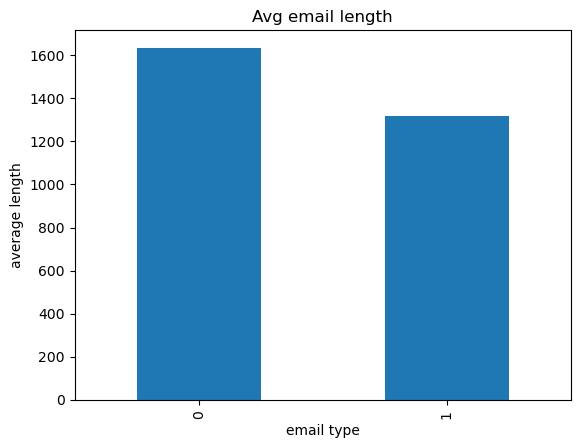

In [53]:
avg_length = df.groupby("spam")["length"].mean()
print(avg_length)
avg_length.plot(kind="bar")
plt.title("Avg email length")
plt.xlabel("email type")
plt.ylabel("average length")
plt.show()